# LangGraph 기반 RAG - Step 2. 문서 평가 + 질문 재작성 루프 (Corrective RAG)
##  인공지능기본법 QA

> Corrective RAG(CRAG): 검색 결과를 평가해 나쁘면 교정 동작  

기본 RAG(`retrieve → generate`, [1-1.basic_rag.ipynb](./1-1.basic_rag.ipynb) 참고)는 검색 결과가 엉뚱해도 그대로 답변한다.
이번 실습에서는 그래프가 **스스로 판단**하게 만든다.

- `grade_documents`: LLM이 각 조문의 질문 관련성을 `yes/no`로 평가해 관련 조문만 남김
- **조건부 Edge**: 관련 조문이 없으면 `rewrite_query`로 질문을 법률 용어로 고쳐 다시 검색 (최대 `MAX_REWRITES`회)
- 끝까지 근거가 없으면 지어내지 않고 "근거를 찾지 못했다"고 답변

```mermaid
flowchart TD
    START([START]) --> retrieve[retrieve]
    retrieve --> grade[grade_documents]
    grade -->|관련 조문 있음| generate[generate]
    generate --> END1([END])
    grade -->|없음 & 재시도 소진| no_evidence[no_evidence]
    no_evidence --> END1
    grade -->|없음 & 재시도 가능| rewrite[rewrite_query]
    rewrite --> retrieve

```

> 사전 조건: Qdrant 실행 중(`cd docker-qdrant && docker compose up -d`) + 색인 완료(`uv run python -m rag.indexer`)
>
> 다음 실습: [1-3.agentic_rag.ipynb](./1-3.agentic_rag.ipynb) (질문 라우팅 + 답변 근거 검증)

## 0. 환경 설정

In [1]:
from typing import Literal, TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from common.ai_model import get_llm_model
from common.config import QDRANT_COLLECTION, RERANK_TOP_N, RETRIEVAL_TOP_K
from common.qdrant import get_qdrant_client
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve

In [2]:
# Qdrant 컬렉션과 색인된 Chunk 수 확인
client = get_qdrant_client()
count = client.count(collection_name=QDRANT_COLLECTION).count
print(f"컬렉션: {QDRANT_COLLECTION} / Chunk 수: {count}")

컬렉션: ai_basic_law / Chunk 수: 3


In [3]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 판단(평가ㆍ재작성)용 LLM과 답변 생성용 LLM
judge_llm = get_llm_model(max_tokens=256, model="gpt-5.4-mini")
answer_llm = get_llm_model(max_tokens=1024, model="gpt-5.4-mini")

### 공통 헬퍼

- `search_law`: `rag` 모듈의 **Hybrid 검색(Dense+BM25, RRF) → LLM Rerank**를 한 번에 호출
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화 (PNG 렌더링 실패 시 Mermaid 텍스트 출력)

In [4]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

In [5]:
docs = search_law("고영향 인공지능이란 무엇인가요?")
print("검색 결과:", format_sources(docs))

검색 결과: 제제1조조(목적)


### 실행 헬퍼 — `stream`으로 노드 실행 경로 추적

`stream_mode="updates"`를 쓰면 노드가 끝날 때마다 `{노드명: 변경된 State}`가 나와, 그래프가 어떤 경로로 움직였는지 볼 수 있다.

In [6]:
def run(graph, question: str) -> dict:
    """그래프를 stream으로 실행하며 방문한 노드 경로를 출력하고 최종 State를 반환한다."""
    print(f"Q. {question}")
    path, final_state = [], {"question": question}
    for update in graph.stream({"question": question}, stream_mode="updates"):
        for node_name, node_output in update.items():
            path.append(node_name)
            final_state.update(node_output or {})
    print("경로:", " → ".join(path))
    print("rewrite_count:", final_state.get("rewrite_count", 0))
    print("근거 조문:", format_sources(final_state.get("documents", [])))
    display(Markdown(final_state["answer"]))
    return final_state

## Step 1 노드 재사용 — `generate`

In [7]:
ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 반드시 주어진 <context>의 조문만 근거로 답하라. "
    "답변 끝에 근거 조문(예: 제2조)을 명시하고, context에 없는 내용은 모른다고 답하라."
)

# answer 노드 정의
def generate_node(state) -> dict:
    context = format_context(state["documents"])
    response = answer_llm.invoke([
        SystemMessage(content=ANSWER_SYSTEM_PROMPT),
        HumanMessage(content=f"질문: {state['question']}\n\n<context>\n{context}\n</context>"),
    ])
    return {"answer": response.content}

## State 정의

In [8]:
MAX_REWRITES = 2
NO_EVIDENCE_ANSWER = "인공지능기본법에서 관련 근거 조문을 찾지 못했습니다."

class CorrectiveState(TypedDict):
    question: str          # 사용자 원 질문 (답변 생성에 사용)
    query: str             # 검색에 쓰는 질문 (재작성될 수 있음)
    documents: list[RetrievedChunk]
    rewrite_count: int
    answer: str

### 구조화 출력(Structured Output)으로 LLM 판단 받기

In [9]:
class RelevanceGrade(BaseModel):
    """조문이 질문에 답하는 데 필요한 정보를 담고 있는지 평가한다."""
    relevant: Literal["yes", "no"] = Field(description="질문과 관련 있으면 yes, 없으면 no")


GRADE_SYSTEM_PROMPT = (
    "너는 법률 검색 결과 평가자다. 조문이 질문에 답하는 데 도움이 되는 내용을 "
    "담고 있으면 yes, 무관하면 no로 평가하라."
)
relevance_grader = judge_llm.with_structured_output(RelevanceGrade, method="function_calling")

# 단독 테스트
sample = docs[0]
grade = relevance_grader.invoke([
    SystemMessage(content=GRADE_SYSTEM_PROMPT),
    HumanMessage(content=f"질문: 고영향 인공지능이란?\n\n조문:\n{sample.chunk.text}"),
])
print(format_sources([sample]), "→", grade.relevant)

제제1조조(목적) → no


### 노드 정의

In [10]:
REWRITE_SYSTEM_PROMPT = (
    "너는 법률 검색 질의 개선 도우미다. 사용자 질문을 인공지능기본법 조문 검색이 잘 되도록 "
    "법률 용어 중심의 한 문장 검색 질의로 다시 써라. 질의 문장만 출력하라."
)


def corrective_retrieve_node(state: CorrectiveState) -> dict:
    query = state.get("query") or state["question"]
    print(f"  [retrieve] query = {query}")
    return {"query": query, "documents": search_law(query)}


def grade_documents_node(state: CorrectiveState) -> dict:
    relevant_docs = []
    for doc in state["documents"]:
        grade = relevance_grader.invoke([
            SystemMessage(content=GRADE_SYSTEM_PROMPT),
            HumanMessage(content=f"질문: {state['question']}\n\n조문:\n{doc.chunk.text}"),
        ])
        if grade.relevant == "yes":
            relevant_docs.append(doc)
    print(f"  [grade] 관련 조문 {len(relevant_docs)}/{len(state['documents'])}: {format_sources(relevant_docs)}")
    return {"documents": relevant_docs}


def rewrite_query_node(state: CorrectiveState) -> dict:
    response = judge_llm.invoke([
        SystemMessage(content=REWRITE_SYSTEM_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    return {"query": response.content.strip(), "rewrite_count": state.get("rewrite_count", 0) + 1}


def no_evidence_node(state: CorrectiveState) -> dict:
    return {"answer": NO_EVIDENCE_ANSWER}

### 조건부 Edge — 다음 노드를 결정하는 함수

`add_conditional_edges`에 넘기는 함수는 State를 보고 **다음에 갈 노드 이름**을 반환한다.

In [11]:
def decide_after_grading(state: CorrectiveState) -> Literal["generate", "rewrite_query", "no_evidence"]:
    if state["documents"]:
        return "generate"
    if state.get("rewrite_count", 0) < MAX_REWRITES:
        return "rewrite_query"
    return "no_evidence"

## 그래프 조립

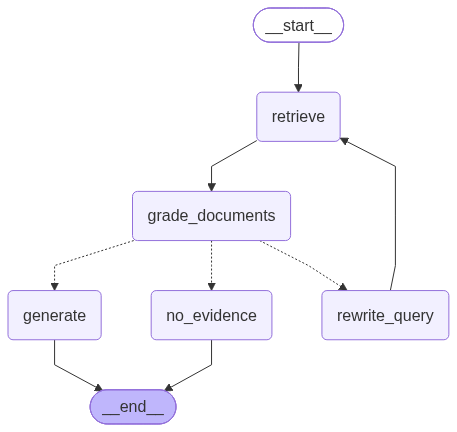

In [12]:
builder = StateGraph(CorrectiveState)
builder.add_node("retrieve", corrective_retrieve_node)
builder.add_node("grade_documents", grade_documents_node)
builder.add_node("rewrite_query", rewrite_query_node)
builder.add_node("generate", generate_node)  # Step 1의 노드 재사용
builder.add_node("no_evidence", no_evidence_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges("grade_documents", decide_after_grading)
builder.add_edge("rewrite_query", "retrieve")
builder.add_edge("generate", END)
builder.add_edge("no_evidence", END)

corrective_graph = builder.compile()
show_graph(corrective_graph)

## 실행

In [13]:
_ = run(corrective_graph, "'고영향 인공지능'이란 무엇인가요?")

Q. '고영향 인공지능'이란 무엇인가요?
  [retrieve] query = '고영향 인공지능'이란 무엇인가요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법상 ‘고영향 인공지능’의 정의 및 요건은 무엇인가?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법상 ‘고영향 인공지능’의 정의 및 요건은 무엇인가?
  [grade] 관련 조문 0/1: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [14]:
_ = run(corrective_graph, "AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?")

Q. AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?
  [retrieve] query = AI 기본법에서 고영향 인공지능 사업자가 지켜야 할 책무는?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법에서 고영향 인공지능 사업자가 준수해야 할 책무에 관한 조문은?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 인공지능기본법에서 고영향 인공지능 사업자가 준수해야 할 책무에 관한 조문은?
  [grade] 관련 조문 0/1: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [15]:
# 법 범위 밖 질문: 관련 조문이 없어 재작성 루프를 돌다가 no_evidence로 종료되는지 확인
_ = run(corrective_graph, "자율주행차 사고가 나면 보험금은 얼마나 받나요?")

Q. 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [retrieve] query = 자율주행차 사고가 나면 보험금은 얼마나 받나요?
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 자율주행자동차 사고 발생 시 보험금 지급 기준 및 보상 범위 관련 인공지능기본법 조문
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 자율주행자동차 사고 발생 시 보험금 지급 기준 및 보상 범위 관련 인공지능기본법 조문
  [grade] 관련 조문 0/1: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

In [16]:
# 다른 문제 질문
_ = run(corrective_graph, "파이썬 언어에 대해 설명해줘")

Q. 파이썬 언어에 대해 설명해줘
  [retrieve] query = 파이썬 언어에 대해 설명해줘
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 파이썬 언어에 관한 인공지능기본법상 정의, 적용 범위 및 관련 규정을 검색할 수 있도록 조문에서 사용된 법률 용어 중심으로 질의하라.
  [grade] 관련 조문 0/1: (없음)
  [retrieve] query = 파이썬 언어에 관한 인공지능기본법상 정의, 적용 범위 및 관련 규정을 검색할 수 있도록 조문에서 사용된 법률 용어 중심으로 질의하라.
  [grade] 관련 조문 0/1: (없음)
경로: retrieve → grade_documents → rewrite_query → retrieve → grade_documents → rewrite_query → retrieve → grade_documents → no_evidence
rewrite_count: 2
근거 조문: (없음)


인공지능기본법에서 관련 근거 조문을 찾지 못했습니다.

---
## 정리

| 핵심 LangGraph 개념 | 재사용한 `rag/` 모듈 |
|---------------------|---------------------|
| `add_conditional_edges`, 루프, `with_structured_output`, `stream` | `retriever.retrieve`, `reranker.rerank`, `chunker.format_article_label` |

**다음 실습**: [1-3.agentic_rag.ipynb](./1-3.agentic_rag.ipynb) — 그래프의 입구(라우팅)와 출구(근거 검증)에 판단 노드를 추가한다.